# Cleaning one histology section

`cleanslide` removes mounting artifacts from a histology section and returns a
tissue mask, a registration-ready grayscale image, and the colour section with
its background removed.

This demo runs the whole pipeline on a single section and shows what each stage
contributes. It needs the optional plotting extra:

```bash
pip install 'cleanslide[qc]'
```

Every size parameter is a physical quantity in micrometres, converted to pixels
from the section's own pixel size.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cleanslide import CleanParams, clean_section, um_to_px

## The section

Point `CLEANSLIDE_DEMO_SECTION` at a brightfield histology section. Without
one, a synthetic section is generated so the notebook still runs end to end.

As run here: **NextBrain subject P57-16, block P3.1, section 09** — Luxol Fast
Blue at 4.0 µm/px, from

> Iglesias Gonzalez, E.; Casamitjana, A.; Atzeni, A.; Billot, B.; Thomas, D.;
> Blackburn, E.; et al. (2023). *Registered histology, MRI, and manual
> annotations of over 300 brain regions in 5 human hemispheres (data from ERC
> Starting Grant 677697 "BUNGEE-TOOLS")*. University College London. Dataset.
> <https://doi.org/10.5522/04/24243835.v1>

Released under [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/).
Every image below is derived from it by `cleanslide`.

The pixel size matters more than anything else here: every filter is sized in
micrometres and converted through it, so a wrong value does not raise an error,
it silently rescales the whole pipeline.

sub-NBP5716_sample-P3109_stain-LFB_BF.tif
11899 x 14994 px at 4.0 um/px


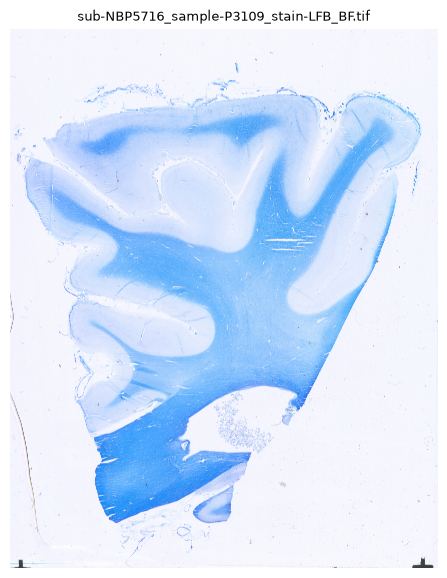

In [2]:
def load_section():
    """Return (image, pixel_size_um, label) from the environment or synthesize one."""
    path = os.environ.get("CLEANSLIDE_DEMO_SECTION", "")
    if path and Path(path).exists():
        import cv2
        cv2.setUseOptimized(True)
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        return rgb, float(os.environ.get("CLEANSLIDE_DEMO_PIXEL_SIZE_UM", 4.0)), Path(path).name

    import cv2
    rng = np.random.default_rng(0)
    rgb = np.full((900, 700, 3), 248, np.uint8)
    cv2.ellipse(rgb, (350, 450), (250, 380), 0, 0, 360, (150, 130, 180), -1)
    cv2.ellipse(rgb, (350, 450), (140, 240), 0, 0, 360, (95, 75, 130), -1)
    rgb = np.clip(rgb + rng.normal(0, 6, rgb.shape), 0, 255).astype(np.uint8)
    cv2.circle(rgb, (300, 330), 47, (248, 248, 248), -1)      # a mounting bubble
    return rgb, 31.75, "synthetic section (no demo image found)"


rgb, pixel_size_um, label = load_section()
print(f"{label}\n{rgb.shape[1]} x {rgb.shape[0]} px at {pixel_size_um} um/px")

plt.figure(figsize=(6, 7))
plt.imshow(rgb)
plt.title(label, fontsize=9)
plt.axis("off")
plt.show()

## Running the pipeline

One call. Nothing else is configured: the background level and the contrast
endpoints are estimated from this section, because they depend on the scan
rather than on the tissue.

`keep_stages=True` retains the intermediate images so we can look at them; a
batch run leaves it off and keeps only the outputs.

In [3]:
result = clean_section(rgb, pixel_size_um, keep_stages=True)

print("estimated from the image:")
for key in ("background_threshold", "normalise_low", "normalise_high"):
    if key in result.info:
        print(f"  {key:24} {result.info[key]}")

estimated from the image:
  background_threshold     242
  normalise_low            10.0
  normalise_high           131.0


## The three outputs

- **grayscale tissue image** — the section with the background remove, and inverted to grayscale image. This is what a registration step consumes.
- **colour tissue image** — the section with the background removed. Keeps the stain visible.
- **tissue mask** — binary mask. 

### Why the grayscale is inverted

Not cosmetic. These sections are registered to a **T1 MRI**, so the cleaned image is made to resemble a T1 as closely as possible.

| | white matter | grey matter | background |
|---|---|---|---|
| T1 MRI | bright | darker | dark |
| stained histology | **dark** (myelin takes the stain) | lighter | **near-white** (glass) |
| after inversion | bright | darker | dark (set to 0) |

Inverting restores the T1 ordering, and the background is set to 0 rather than inverted to white, which matches a skull-stripped T1. The registration's similarity measure then compares like with like instead of having to bridge an
inverted contrast.

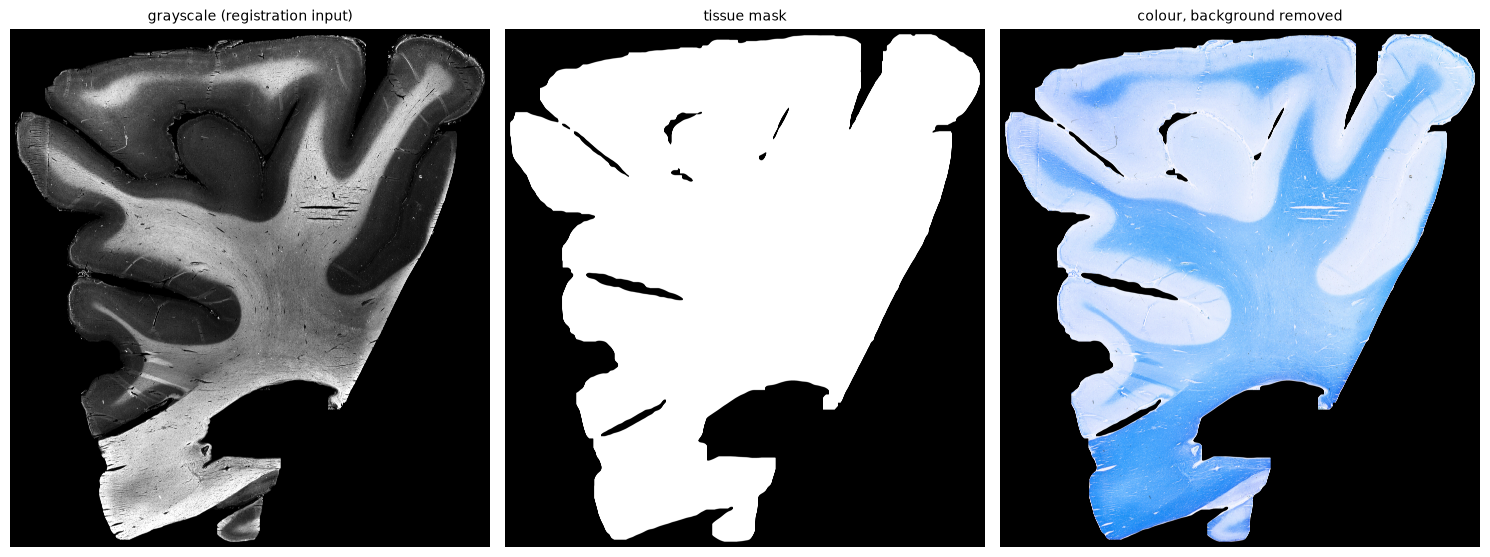

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for axis, (image, title) in zip(axes, [
        (result.clean, "grayscale (registration input)"),
        (result.mask, "tissue mask"),
        (result.rgb, "colour, background removed")]):
    axis.imshow(image, cmap=None if image.ndim == 3 else "gray",
                vmin=None if image.ndim == 3 else 0,
                vmax=None if image.ndim == 3 else 255)
    axis.set_title(title, fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

## What each stage did

- the mask is generated from luminance, not from stain concentration: the RGB is
  reduced to a single intensity channel, the background mode is located in the
  intensity histogram and the threshold placed at its lower shoulder, the
  resulting binary foreground is Gaussian-blurred and re-thresholded by Otsu so
  intra-tissue gaps merge into one connected region, and that is morphologically
  opened and filtered on connected-component extent, aspect ratio and area to
  reject printed calibration charts, slide labels and debris
- the mask isolates tissue from glass
- round bubbles are inpainted out of the colour image
- the mask edge is smoothed, so the masked tissue has no ragged pixel border
- inversion makes tissue bright
- the stretch opens up the compressed range a pale stain inverts into
- a local contrast enhancement finishes the grayscale

### No optical density, no colour deconvolution

Luminance needs no per-stain configuration and works identically on H&E,
LFB-PAS and DAB-TBB. The alternatives were tried and each fails for its own
reason:

| Method | Why not |
|---|---|
| mean OD | white/grey matter CNR 2.66 vs 2.69 for luminance — no contrast gained |
| Ruifrok–Johnston [1] | assumes a fixed chromogen count: DAB-TBB has one, LFB-PAS has two |
| Macenko [2] | its \|OD\| ≥ 0.15 cutoff discards the faint PAS cortex before fitting |

A printed colour chart in the scan also fabricates a convincing stain vector,
and it is sometimes the largest connected component, so it cannot be dropped by
size.

[1] Ruifrok AC, Johnston DA. Quantification of histochemical staining by colour
deconvolution. *Anal Quant Cytol Histol* 23:291–299, 2001.
[2] Macenko M, Niethammer M, Marron JS, et al. A method for normalizing
histology slides for quantitative analysis. *IEEE ISBI* 1107–1110, 2009.
[doi:10.1109/ISBI.2009.5193250](https://doi.org/10.1109/ISBI.2009.5193250)

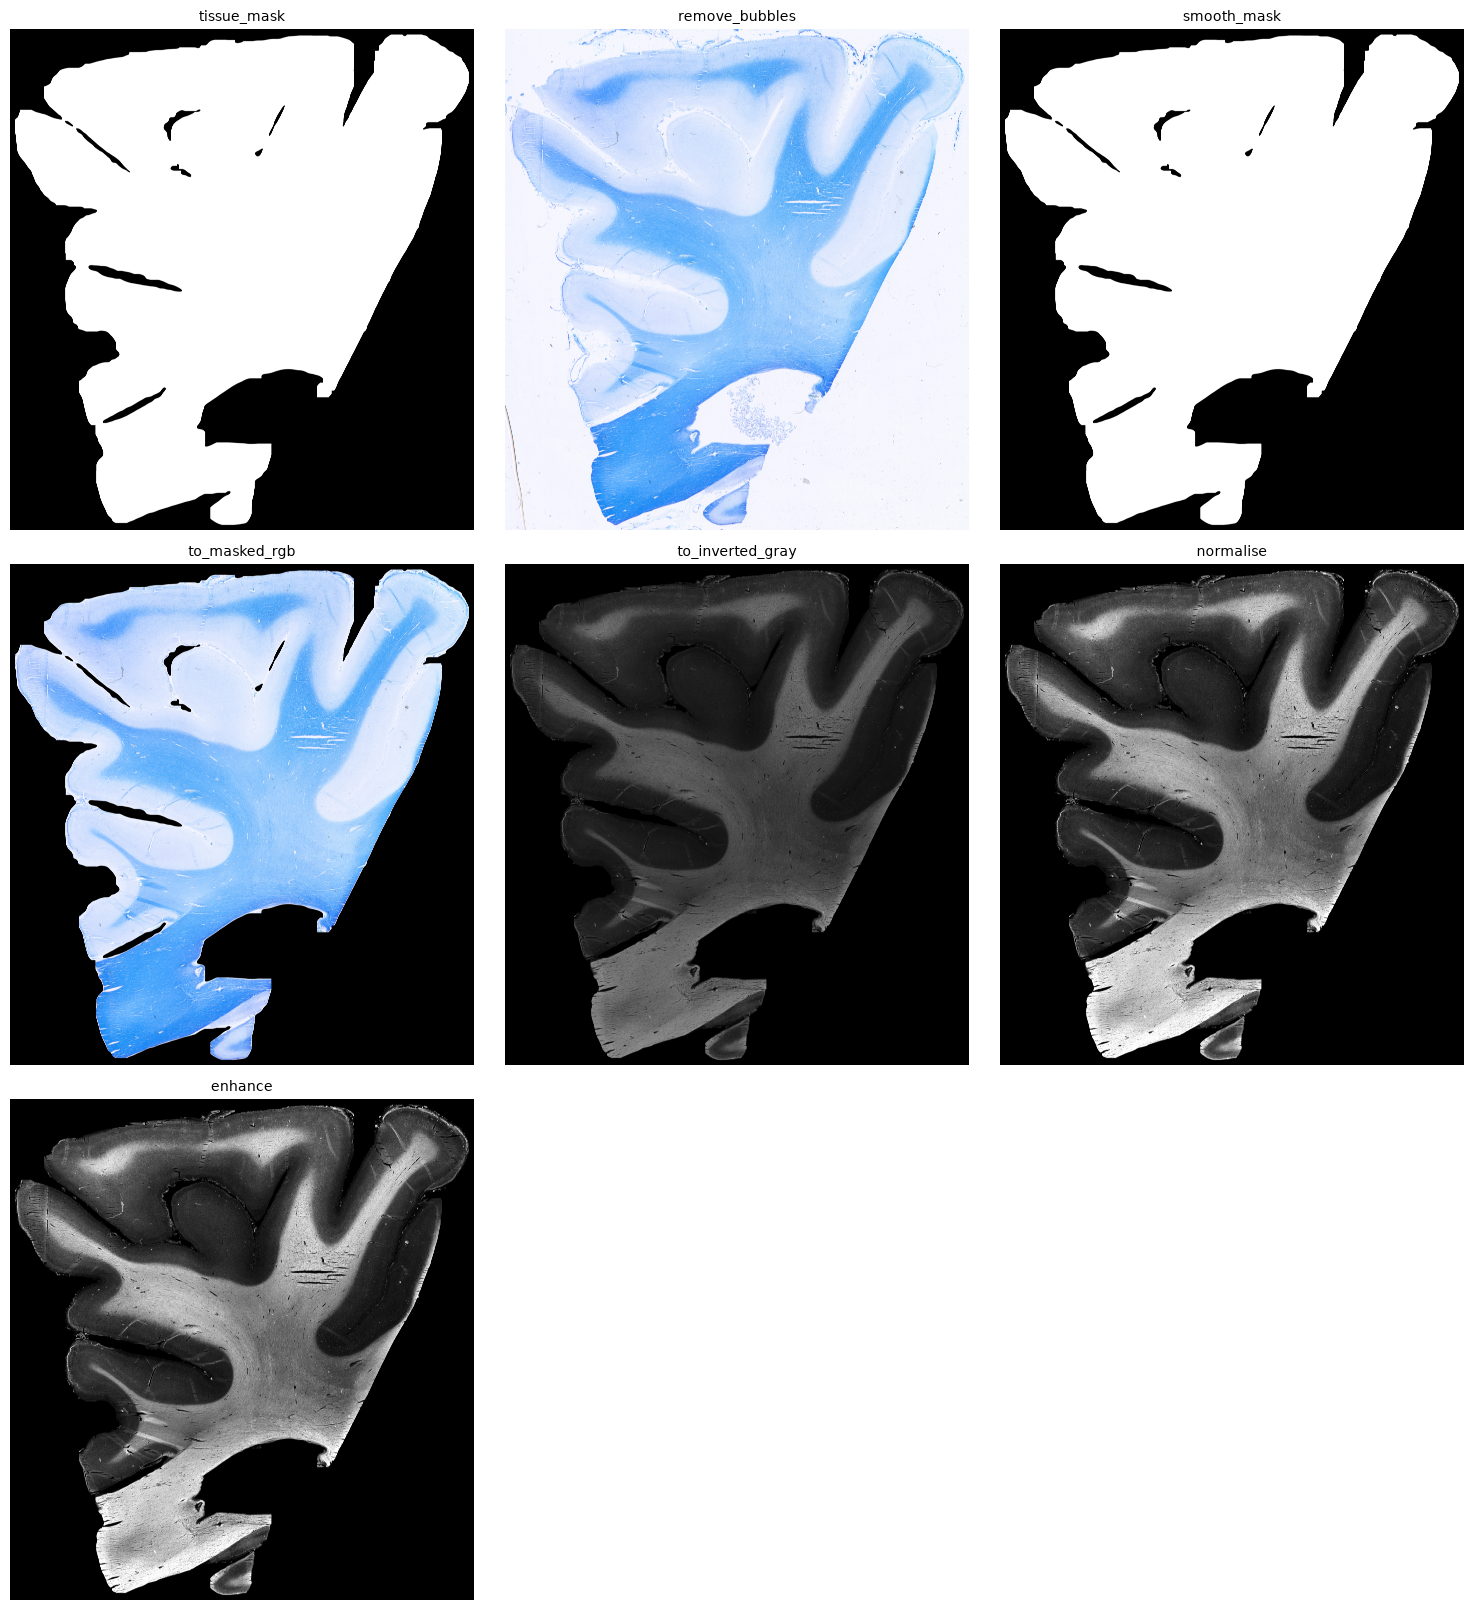

In [5]:
stages_shown = [(name, result.intermediates[name])
                for name in result.intermediates]

columns = 3
rows = (len(stages_shown) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5.4 * rows),
                         squeeze=False)
for axis, (name, image) in zip(axes.flat, stages_shown):
    axis.imshow(image, cmap=None if image.ndim == 3 else "gray",
                vmin=None if image.ndim == 3 else 0,
                vmax=None if image.ndim == 3 else 255)
    axis.set_title(name, fontsize=10)
    axis.axis("off")
for axis in axes.flat[len(stages_shown):]:
    axis.axis("off")
plt.tight_layout()
plt.show()